## 1. Setup and configuration

In [4]:
import os, sys, json, random, time, math, shutil, subprocess, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2.functional as TF

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

IN_COLAB = "google.colab" in sys.modules

# ---- where persistent files live (checkpoints, cache, metadata) ----
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path(os.environ.get("WORK_DIR", "/content/drive/MyDrive/shoplifting_project"))
    DATA_DIR = Path("/content/data")            # raw videos: local disk (fast), re-downloaded only if needed
else:
    WORK_DIR = Path(os.environ.get("WORK_DIR", "./shoplifting_project"))
    DATA_DIR = WORK_DIR / "data"

CACHE_DIR = WORK_DIR / "cache"
CKPT_DIR  = WORK_DIR / "checkpoints"
for d in (WORK_DIR, DATA_DIR, CACHE_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    drive_file_id = "1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-",
    T             = 16,      # frames sampled per video
    cache_size    = 144,     # frames are stored at cache_size x cache_size
    img_size      = 112,     # network input size (random crop for training)
    batch_size    = int(os.environ.get("BATCH_SIZE", 16)),
    epochs        = int(os.environ.get("EPOCHS", 40)),
    lr            = 1e-3,
    weight_decay  = 1e-2,
    patience      = 10,      # early stopping on val F1
    seed          = 42,
    val_frac      = 0.15,
    test_frac     = 0.15,
    num_workers   = int(os.environ.get("NUM_WORKERS", min(4, os.cpu_count() or 1))),
)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| work dir:", WORK_DIR.resolve())

device: cuda | work dir: /kaggle/working/shoplifting_project


## 2. Download the dataset with `wget`
The download is skipped when the frame cache is already complete or the videos are already on disk.
The Drive file must be shared as *Anyone with the link*.

In [5]:
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".mpg", ".mpeg", ".wmv", ".flv", ".webm"}
META_CSV = WORK_DIR / "metadata.csv"
ZIP_PATH = DATA_DIR / "Shop_DataSet.zip"

def list_videos(root):
    return sorted(p for p in Path(root).rglob("*") if p.suffix.lower() in VIDEO_EXTS)

def cache_complete():
    if not META_CSV.exists():
        return False
    meta = pd.read_csv(META_CSV)
    return all((CACHE_DIR / f"{i}.npy").exists() for i in meta["id"])

def wget_drive(file_id, out_path):
    url = f"https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t"
    subprocess.run(["wget", "--no-check-certificate", "-q", "--show-progress", "-O", str(out_path), url], check=False)
    if not zipfile.is_zipfile(out_path):                      # fallback if wget got an HTML page
        print("wget did not return a zip, falling back to gdown ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
        gdown.download(id=file_id, output=str(out_path), quiet=False)
    assert zipfile.is_zipfile(out_path), "Download failed. Check that the Drive link is public."

if cache_complete():
    print("Frame cache already complete -> download skipped.")
elif list_videos(DATA_DIR):
    print(f"{len(list_videos(DATA_DIR))} videos already on disk -> download skipped.")
else:
    if not ZIP_PATH.exists():
        wget_drive(CFG["drive_file_id"], ZIP_PATH)
    print("Extracting ...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    ZIP_PATH.unlink(missing_ok=True)                           # save disk space
    print("Videos found:", len(list_videos(DATA_DIR)))

855 videos already on disk -> download skipped.


## 3. Explore the dataset
Labels are inferred from the folder names (`non shop lifters` / `normal` -> 0, `shop lifters` / `shoplift*` / `theft` -> 1). Metadata is cached in `metadata.csv`.

probing videos:   0%|          | 0/855 [00:00<?, ?it/s]

Metadata built.

Clips per class:
 label
normal         531
shoplifting    324

Duration (s) / frames per class:
label                 0       1
duration count   531.00  324.00
         mean     13.93   12.22
         std       5.37    3.35
         min       3.00    4.00
         25%      11.00   10.00
         50%      14.00   12.00
         75%      16.00   15.00
         max      74.00   23.03
n_frames count   531.00  324.00
         mean    347.78  304.60
         std     134.20   83.47
         min      75.00  100.00
         25%     275.00  248.00
         50%     348.00  300.00
         75%     400.00  372.00
         max    1850.00  570.00

Frame resolutions:
 width  height
704    576       855


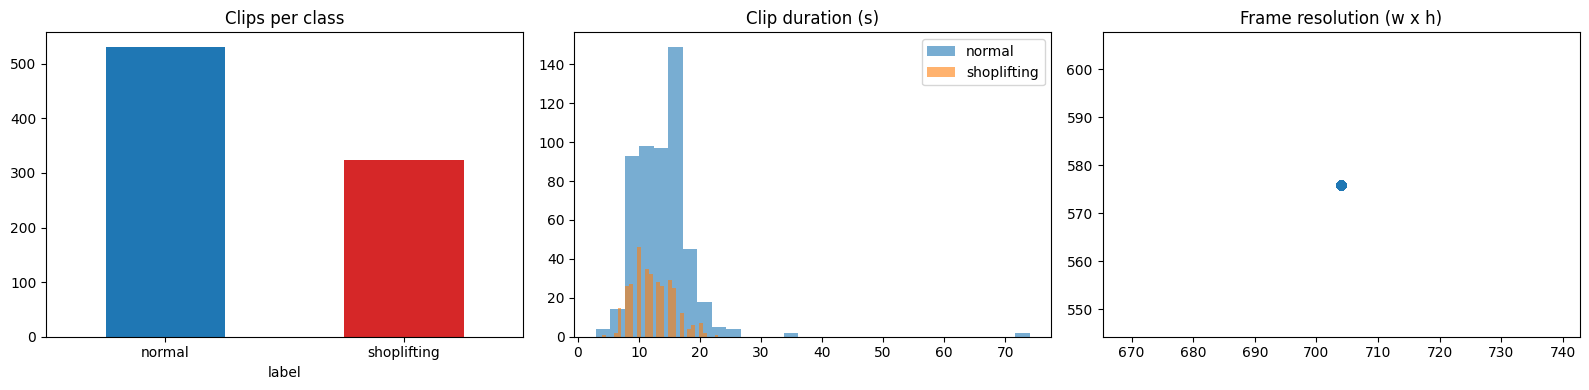

In [6]:
def infer_label(path):
    """Label from the parent folder name. Negative keywords are checked first ('non shop lifters' contains 'shop lift')."""
    folder = Path(path).parent.name.lower().replace("_", " ").replace("-", " ")
    if any(k in folder for k in ("non shop", "nonshop", "non-shop", "normal", "not shop")):
        return 0
    if any(k in folder for k in ("shop lift", "shoplift", "theft", "steal")):
        return 1
    return None

def probe_video(path):
    cap = cv2.VideoCapture(str(path))
    n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return n, fps, w, h

def build_metadata():
    videos = list_videos(DATA_DIR)
    assert videos, f"No videos found under {DATA_DIR}"
    rows = []
    for p in tqdm(videos, desc="probing videos"):
        label = infer_label(p)
        if label is None:
            continue
        n, fps, w, h = probe_video(p)
        if n <= 0 or w <= 0:
            print("skipping unreadable video:", p); continue
        rows.append(dict(path=str(p), label=label, n_frames=n, fps=fps, duration=n / fps, width=w, height=h))
    if not rows:
        tree = sorted({str(p.parent.relative_to(DATA_DIR)) for p in videos})[:20]
        raise RuntimeError(f"Could not infer labels from folders. Folders seen: {tree}")
    meta = pd.DataFrame(rows).reset_index(names="id")
    meta.to_csv(META_CSV, index=False)
    return meta

if META_CSV.exists() and cache_complete():
    meta = pd.read_csv(META_CSV)
    print("Loaded cached metadata.")
else:
    meta = build_metadata()
    print("Metadata built.")

CLASS_NAMES = ["normal", "shoplifting"]
print("\nClips per class:\n", meta["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().to_string())
print("\nDuration (s) / frames per class:")
print(meta.groupby("label")[["duration", "n_frames"]].describe().T.round(2).to_string())
print("\nFrame resolutions:\n", meta.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
meta["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], rot=0)
ax[0].set_title("Clips per class")
for lbl, name in enumerate(CLASS_NAMES):
    ax[1].hist(meta.loc[meta.label == lbl, "duration"], bins=30, alpha=.6, label=name)
ax[1].set_title("Clip duration (s)"); ax[1].legend()
ax[2].scatter(meta["width"], meta["height"], alpha=.4); ax[2].set_title("Frame resolution (w x h)")
plt.tight_layout(); plt.show()

## 4. Uniform frame sampling
For a video with `N` frames and target `T`, the skip interval is `skip = N / T`. The video is split into `T` equal segments and the **centre frame of each segment** is taken:

`idx_i = floor(skip * i + skip / 2)`, for `i = 0 ... T-1`

The samples therefore span the whole clip evenly (gaps differ by at most 1 frame). If `N < T`, frames are repeated evenly.

N=     1 skip=    0.06 -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
N=     5 skip=    0.31 -> [0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4]
N=    15 skip=    0.94 -> [0, 1, 2, 3, 4, 5, 6, 7, 7, 8, 9, 10, 11, 12, 13, 14]
N=    16 skip=    1.00 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
N=    17 skip=    1.06 -> [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16]
N=    31 skip=    1.94 -> [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]
N=   100 skip=    6.25 -> [3, 9, 15, 21, 28, 34, 40, 46, 53, 59, 65, 71, 78, 84, 90, 96]
N=   257 skip=   16.06 -> [8, 24, 40, 56, 72, 88, 104, 120, 136, 152, 168, 184, 200, 216, 232, 248]
N=  1000 skip=   62.50 -> [31, 93, 156, 218, 281, 343, 406, 468, 531, 593, 656, 718, 781, 843, 906, 968]
N= 12345 skip=  771.56 -> [385, 1157, 1928, 2700, 3472, 4243, 5015, 5786, 6558, 7329, 8101, 8872, 9644, 10416, 11187, 11959]

Frame sampling verified for all lengths.


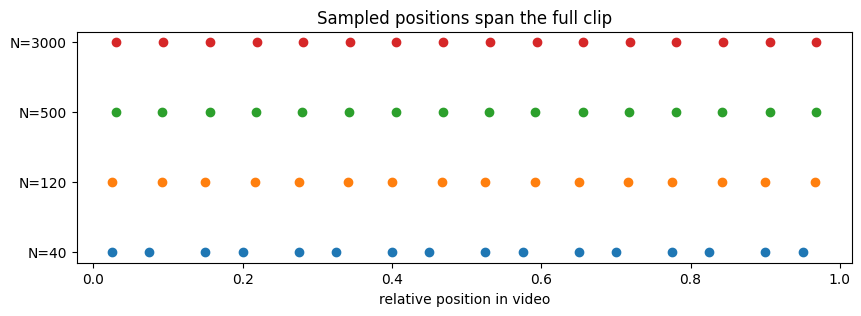

In [7]:
def uniform_sample_indices(n_frames: int, T: int) -> np.ndarray:
    """Return T frame indices spread uniformly over [0, n_frames)."""
    if n_frames <= 0:
        raise ValueError("n_frames must be positive")
    if n_frames < T:                                           # short video: repeat frames evenly
        idx = np.linspace(0, n_frames - 1, T).round()
    else:
        skip = n_frames / T                                    # uniform skip interval
        idx = np.floor(skip * np.arange(T) + skip / 2)
    return np.clip(idx.astype(int), 0, n_frames - 1)

# ---- verification on clips of very different lengths ----
test_lengths = [1, 5, 15, 16, 17, 31, 100, 257, 1000, 12345]
T = CFG["T"]
for n in test_lengths:
    idx = uniform_sample_indices(n, T)
    assert len(idx) == T and idx.min() >= 0 and idx.max() < n and np.all(np.diff(idx) >= 0)
    if n >= T:
        skip = n / T
        gaps = np.diff(idx)
        assert gaps.max() - gaps.min() <= 1, "gaps must be uniform within 1 frame"
        assert idx[0] < skip and idx[-1] >= n - skip, "samples must span the whole clip"
    print(f"N={n:>6} skip={n / T:8.2f} -> {idx.tolist()}")
print("\nFrame sampling verified for all lengths.")

fig, ax = plt.subplots(figsize=(10, 3))
for k, n in enumerate([40, 120, 500, 3000]):
    ax.scatter(uniform_sample_indices(n, T) / n, [k] * T)
ax.set_yticks(range(4)); ax.set_yticklabels(["N=40", "N=120", "N=500", "N=3000"])
ax.set_xlabel("relative position in video"); ax.set_title("Sampled positions span the full clip"); plt.show()

## 5. Read sampled frames and cache them
Each video is decoded **once**: `T` uniformly sampled frames are resized to `cache_size x cache_size` and stored as a uint8 `.npy`. Training then never touches the video decoder again, which makes epochs very fast and the stage resumable (existing files are skipped).

In [8]:
def count_frames_by_grab(path):
    cap = cv2.VideoCapture(str(path)); n = 0
    while cap.grab():
        n += 1
    cap.release()
    return n

def read_sampled_frames(path, T, size, n_hint=None):
    """Decode a video once and return a uint8 array (T, size, size, 3) in RGB."""
    n = n_hint or count_frames_by_grab(path)
    for attempt in range(2):
        idx = uniform_sample_indices(n, T)
        wanted = {}
        for pos, i in enumerate(idx):
            wanted.setdefault(int(i), []).append(pos)
        frames = [None] * T
        cap = cv2.VideoCapture(str(path)); i = 0; last_needed = max(wanted)
        while i <= last_needed:
            ok, frame = cap.read()
            if not ok:
                break
            if i in wanted:
                rgb = cv2.cvtColor(cv2.resize(frame, (size, size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
                for pos in wanted[i]:
                    frames[pos] = rgb
            i += 1
        cap.release()
        if all(f is not None for f in frames):
            return np.stack(frames)
        n = count_frames_by_grab(path)                         # metadata frame count was wrong -> recount, retry
    last = next((f for f in reversed(frames) if f is not None), None)
    if last is None:
        raise RuntimeError(f"Cannot decode {path}")
    return np.stack([f if f is not None else last for f in frames])

def cache_one(row):
    out = CACHE_DIR / f"{row.id}.npy"
    if out.exists():
        return None
    try:
        arr = read_sampled_frames(row.path, CFG["T"], CFG["cache_size"], int(row.n_frames))
        np.save(out, arr)
        return None
    except Exception as e:
        return (row.id, row.path, str(e))

if cache_complete():
    print("Frame cache already complete -> skipped.")
else:
    todo = [r for r in meta.itertuples() if not (CACHE_DIR / f"{r.id}.npy").exists()]
    print(f"Caching {len(todo)} / {len(meta)} videos ...")
    with ThreadPoolExecutor(max_workers=CFG["num_workers"] or 1) as ex:
        errors = [e for e in tqdm(ex.map(cache_one, todo), total=len(todo)) if e]
    if errors:
        print(f"{len(errors)} videos failed and are dropped:", errors[:3])
        meta = meta[~meta["id"].isin([e[0] for e in errors])].reset_index(drop=True)
        meta.to_csv(META_CSV, index=False)
    print("Done.")

Caching 855 / 855 videos ...


  0%|          | 0/855 [00:00<?, ?it/s]

Done.


## 6. Stratified train / val / test split (saved to `splits.csv`)

In [9]:
SPLIT_CSV = WORK_DIR / "splits.csv"
if SPLIT_CSV.exists() and set(pd.read_csv(SPLIT_CSV)["id"]) == set(meta["id"]):
    splits = pd.read_csv(SPLIT_CSV)
else:
    train_val, test = train_test_split(meta, test_size=CFG["test_frac"], stratify=meta["label"], random_state=CFG["seed"])
    train, val = train_test_split(train_val, test_size=CFG["val_frac"] / (1 - CFG["test_frac"]),
                                  stratify=train_val["label"], random_state=CFG["seed"])
    splits = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
    splits.to_csv(SPLIT_CSV, index=False)

train_df, val_df, test_df = [splits[splits.split == s].reset_index(drop=True) for s in ("train", "val", "test")]
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASS_NAMES))))

label  normal  shoplifting
split                     
test       80           49
train     371          226
val        80           49


## 7. Consistent spatial augmentation
Random parameters (crop box, flip, brightness, contrast, saturation, hue) are **sampled once per clip** and applied to *all* `T` frames, so the motion between frames is preserved. Validation and test use only a deterministic centre crop.

In [10]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

class ClipAugment:
    """Applies identical spatial/color augmentation to every frame of a (T, C, H, W) clip."""
    def __init__(self, out_size=112, train=True, scale=(0.6, 1.0), ratio=(0.85, 1.18),
                 flip_p=0.5, brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05):
        self.out_size, self.train, self.scale, self.ratio = out_size, train, scale, ratio
        self.flip_p, self.bri, self.con, self.sat, self.hue = flip_p, brightness, contrast, saturation, hue

    def sample_params(self, H, W):
        """Draw ONE set of random parameters for the whole clip."""
        area = H * W * random.uniform(*self.scale)
        r = math.exp(random.uniform(math.log(self.ratio[0]), math.log(self.ratio[1])))
        w = min(W, int(round(math.sqrt(area * r)))); h = min(H, int(round(math.sqrt(area / r))))
        return dict(top=random.randint(0, H - h), left=random.randint(0, W - w), h=h, w=w,
                    flip=random.random() < self.flip_p,
                    bri=random.uniform(1 - self.bri, 1 + self.bri), con=random.uniform(1 - self.con, 1 + self.con),
                    sat=random.uniform(1 - self.sat, 1 + self.sat), hue=random.uniform(-self.hue, self.hue))

    def apply(self, x, p):
        """x: float (T,C,H,W) in [0,1]; the same params p are used for every frame."""
        x = TF.resized_crop(x, p["top"], p["left"], p["h"], p["w"], [self.out_size, self.out_size], antialias=True)
        if p["flip"]:
            x = TF.horizontal_flip(x)
        x = TF.adjust_brightness(x, p["bri"]); x = TF.adjust_contrast(x, p["con"])
        x = TF.adjust_saturation(x, p["sat"]);  x = TF.adjust_hue(x, p["hue"])
        return x.clamp(0, 1)

    def __call__(self, clip_uint8, params=None):
        x = clip_uint8.float() / 255.0
        T, C, H, W = x.shape
        if self.train:
            x = self.apply(x, params or self.sample_params(H, W))
        else:                                                  # deterministic centre crop
            s = int(round(H * 0.875)) if H > self.out_size else H
            x = TF.resized_crop(x, (H - s) // 2, (W - s) // 2, s, s, [self.out_size, self.out_size], antialias=True)
        return (x - MEAN) / STD

## 8. PyTorch `Dataset` returning `(T, C, H, W)`

train:  597 clips, tensor shape (16, 3, 112, 112)  (T, C, H, W)
val  :  129 clips, tensor shape (16, 3, 112, 112)  (T, C, H, W)
test :  129 clips, tensor shape (16, 3, 112, 112)  (T, C, H, W)

Augmentation verified: identical parameters for all frames of a clip.


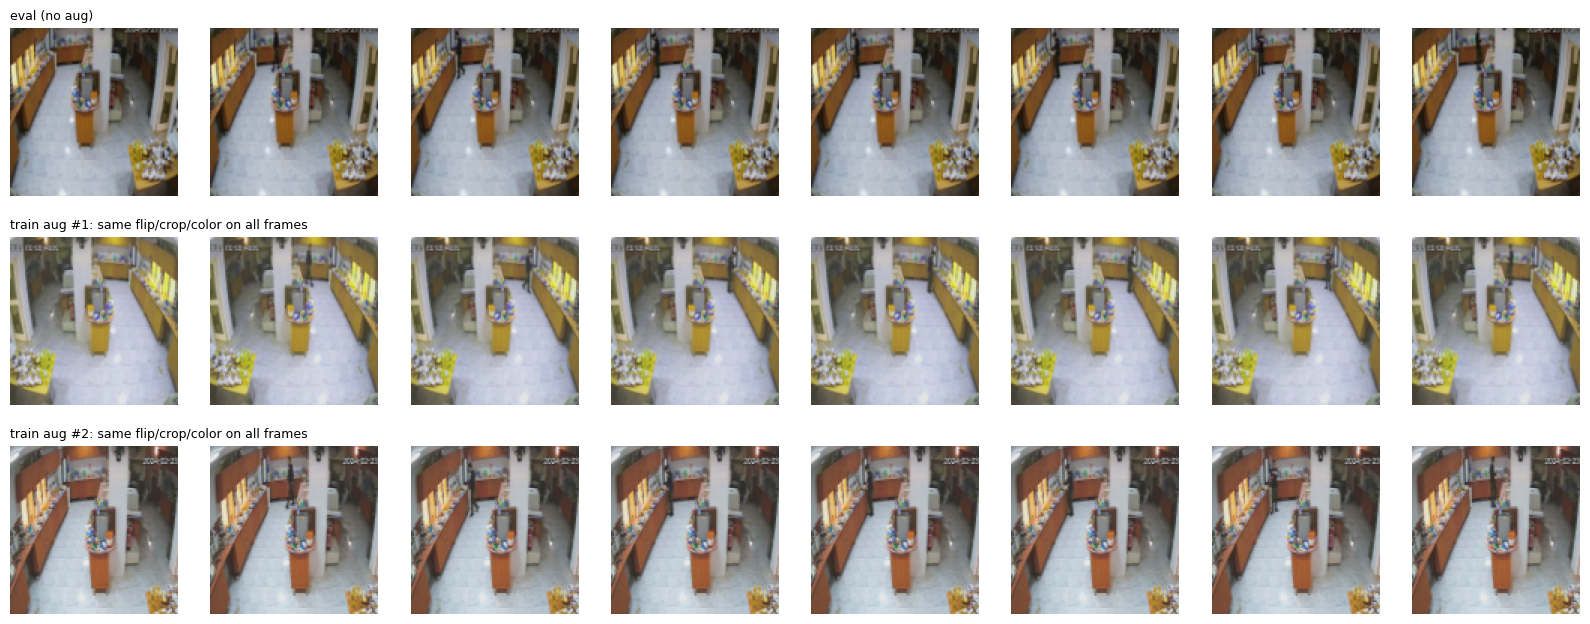

In [11]:
class ShopliftingDataset(Dataset):
    """Loads cached frames of one video and returns (clip[T,C,H,W] float32, label)."""
    def __init__(self, df, cache_dir, transform):
        self.ids, self.labels = df["id"].tolist(), df["label"].tolist()
        self.cache_dir, self.transform = Path(cache_dir), transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        arr = np.load(self.cache_dir / f"{self.ids[i]}.npy")                # (T, H, W, 3) uint8
        clip = torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()      # (T, C, H, W)
        return self.transform(clip), torch.tensor(self.labels[i], dtype=torch.float32)

aug_train = ClipAugment(CFG["img_size"], train=True)
aug_eval  = ClipAugment(CFG["img_size"], train=False)
train_ds = ShopliftingDataset(train_df, CACHE_DIR, aug_train)
val_ds   = ShopliftingDataset(val_df,   CACHE_DIR, aug_eval)
test_ds  = ShopliftingDataset(test_df,  CACHE_DIR, aug_eval)

# ---- shape check on every split ----
expected = (CFG["T"], 3, CFG["img_size"], CFG["img_size"])
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    shapes = {tuple(ds[i][0].shape) for i in range(min(len(ds), 20))}
    assert shapes == {expected}, shapes
    print(f"{name:5s}: {len(ds):4d} clips, tensor shape {shapes.pop()}  (T, C, H, W)")

# ---- check: augmentation is identical across frames ----
clip = torch.from_numpy(np.load(CACHE_DIR / f"{train_df.id[0]}.npy")).permute(0, 3, 1, 2).contiguous()
p = aug_train.sample_params(*clip.shape[-2:])
whole = aug_train(clip, params=p)                                                   # whole clip at once
per_frame = torch.cat([aug_train(clip[t:t + 1], params=p) for t in range(clip.shape[0])])  # frame by frame, same params
assert torch.allclose(whole, per_frame, atol=1e-5), "augmentation differs between frames!"
static = clip[:1].repeat(clip.shape[0], 1, 1, 1)                                    # identical frames in -> identical frames out
out = aug_train(static)
assert all(torch.allclose(out[0], out[t], atol=1e-5) for t in range(1, out.shape[0]))
print("\nAugmentation verified: identical parameters for all frames of a clip.")

def show_clip(x, ax_row, title):
    x = (x * STD + MEAN).clamp(0, 1)
    for k, a in enumerate(ax_row):
        a.imshow(x[k * (x.shape[0] // len(ax_row))].permute(1, 2, 0)); a.axis("off")
    ax_row[0].set_title(title, loc="left", fontsize=9)

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
show_clip(aug_eval(clip), axes[0], "eval (no aug)")
for r in (1, 2):
    show_clip(aug_train(clip), axes[r], f"train aug #{r}: same flip/crop/color on all frames")
plt.tight_layout(); plt.show()

## 9. Model: ResNet-style CNN (from scratch) -> BiGRU -> attention
* **FrameEncoder**: 4 residual stages (32 -> 256 channels) + global average pooling, shared across frames.
* **BiGRU** (2 layers, bidirectional) models the temporal order of actions.
* **Attention pooling** weights the frames; the weights also show *which frames* the model finds suspicious.
* Output: one logit (BCE-with-logits loss).

In [12]:
class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.short = nn.Identity() if (cin == cout and stride == 1) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.short(x), inplace=True)

class FrameEncoder(nn.Module):
    def __init__(self, widths=(32, 64, 128, 192, 256)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 2, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        self.stages = nn.Sequential(*[ResBlock(widths[i], widths[i + 1], 2) for i in range(len(widths) - 1)])
        self.out_dim = widths[-1]
    def forward(self, x):
        return F.adaptive_avg_pool2d(self.stages(self.stem(x)), 1).flatten(1)

class CNNBiGRU(nn.Module):
    def __init__(self, hidden=128, layers=2, dropout=0.4):
        super().__init__()
        self.encoder = FrameEncoder()
        self.gru = nn.GRU(self.encoder.out_dim, hidden, layers, batch_first=True, bidirectional=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.attn = nn.Linear(2 * hidden, 1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, 64), nn.ReLU(inplace=True),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, return_attention=False):               # x: (B, T, C, H, W)
        B, T = x.shape[:2]
        feats = self.encoder(x.flatten(0, 1)).view(B, T, -1)   # (B, T, D)
        seq, _ = self.gru(feats)                               # (B, T, 2H)
        w = torch.softmax(self.attn(seq), dim=1)               # (B, T, 1)
        logit = self.head((w * seq).sum(1)).squeeze(1)         # (B,)
        return (logit, w.squeeze(-1)) if return_attention else logit

model = CNNBiGRU().to(DEVICE)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
with torch.no_grad():
    print("forward check:", model.eval()(torch.randn(2, *expected).to(DEVICE)).shape)

trainable parameters: 2,560,034
forward check: torch.Size([2])


## 10. Training with automatic resume
`checkpoints/last.pt` stores model, optimizer, scheduler, AMP scaler, epoch, history and RNG state after **every epoch**. Re-running this cell after a crash or restart continues from the next epoch. `best.pt` stores the best validation F1. Delete the `checkpoints` folder to retrain from scratch.

In [13]:
train_loader = DataLoader(train_ds, CFG["batch_size"], shuffle=True, num_workers=CFG["num_workers"],
                          pin_memory=DEVICE.type == "cuda", drop_last=len(train_ds) > CFG["batch_size"],
                          persistent_workers=CFG["num_workers"] > 0)
val_loader   = DataLoader(val_ds,  CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])
test_loader  = DataLoader(test_ds, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])

n_pos = int(train_df.label.sum()); n_neg = len(train_df) - n_pos
pos_weight = torch.tensor([n_neg / max(n_pos, 1)], device=DEVICE)        # handles class imbalance
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

LAST_CKPT, BEST_CKPT = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt"

def save_checkpoint(path, **state):
    tmp = Path(str(path) + ".tmp")
    torch.save(state, tmp); os.replace(tmp, path)                       # atomic: never leaves a half-written file

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); losses, probs, labels = [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logit = model(x)
        losses.append(criterion(logit.float(), y).item() * len(y))
        probs.append(torch.sigmoid(logit.float()).cpu()); labels.append(y.cpu())
    probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return sum(losses) / len(labels), probs, labels

def metrics_at(probs, labels, thr=0.5):
    pred = (probs >= thr).astype(int)
    return dict(accuracy=accuracy_score(labels, pred), precision=precision_score(labels, pred, zero_division=0),
                recall=recall_score(labels, pred, zero_division=0), f1=f1_score(labels, pred, zero_division=0))

def fit():
    model = CNNBiGRU().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG["lr"], epochs=CFG["epochs"],
                                                    steps_per_epoch=len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    history, start_epoch, best_f1, bad_epochs = [], 0, -1.0, 0

    if LAST_CKPT.exists():                                              # ---- resume ----
        ck = torch.load(LAST_CKPT, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        history, start_epoch, best_f1, bad_epochs = ck["history"], ck["epoch"] + 1, ck["best_f1"], ck["bad_epochs"]
        print(f"Resumed from epoch {start_epoch} (best val F1 so far: {best_f1:.4f})")
    else:
        print("No checkpoint found -> training from scratch.")

    for epoch in range(start_epoch, CFG["epochs"]):
        if bad_epochs >= CFG["patience"]:
            print("Early stopping (restored from checkpoint)."); break
        model.train(); t0, run_loss, n = time.time(), 0.0, 0
        for x, y in tqdm(train_loader, desc=f"epoch {epoch + 1}/{CFG['epochs']}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                loss = criterion(model(x).float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            run_loss += loss.item() * len(y); n += len(y)

        val_loss, vp, vl = evaluate(model, val_loader)
        m = metrics_at(vp, vl)
        history.append(dict(epoch=epoch + 1, train_loss=run_loss / n, val_loss=val_loss, **{f"val_{k}": v for k, v in m.items()}))
        improved = m["f1"] > best_f1
        if improved:
            best_f1, bad_epochs = m["f1"], 0
            save_checkpoint(BEST_CKPT, model=model.state_dict(), epoch=epoch, val_f1=best_f1)
        else:
            bad_epochs += 1
        save_checkpoint(LAST_CKPT, model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                        history=history, best_f1=best_f1, bad_epochs=bad_epochs)
        print(f"epoch {epoch + 1:3d} | train {run_loss / n:.4f} | val {val_loss:.4f} | acc {m['accuracy']:.3f} "
              f"| P {m['precision']:.3f} | R {m['recall']:.3f} | F1 {m['f1']:.3f} {'*' if improved else ''} | {time.time() - t0:.0f}s")
    return pd.DataFrame(history)

history = fit()
history.to_csv(WORK_DIR / "history.csv", index=False)

No checkpoint found -> training from scratch.


epoch 1/40:   0%|          | 0/37 [00:00<?, ?it/s]

epoch   1 | train 0.8692 | val 0.8640 | acc 0.620 | P 0.000 | R 0.000 | F1 0.000 * | 16s


epoch 2/40:   0%|          | 0/37 [00:00<?, ?it/s]

epoch   2 | train 0.8630 | val 0.8616 | acc 0.620 | P 0.000 | R 0.000 | F1 0.000  | 14s


...

epoch  16 | train 0.8635 | val 0.8625 | acc 0.620 | P 0.000 | R 0.000 | F1 0.000  | 15s


epoch 17/40:   0%|          | 0/37 [00:00<?, ?it/s]

epoch  17 | train 0.8616 | val 0.8618 | acc 0.620 | P 0.000 | R 0.000 | F1 0.000  | 15s


epoch 18/40:   0%|          | 0/37 [00:00<?, ?it/s]

epoch  18 | train 0.8630 | val 0.8617 | acc 0.620 | P 0.000 | R 0.000 | F1 0.000  | 15s
Early stopping (restored from checkpoint).


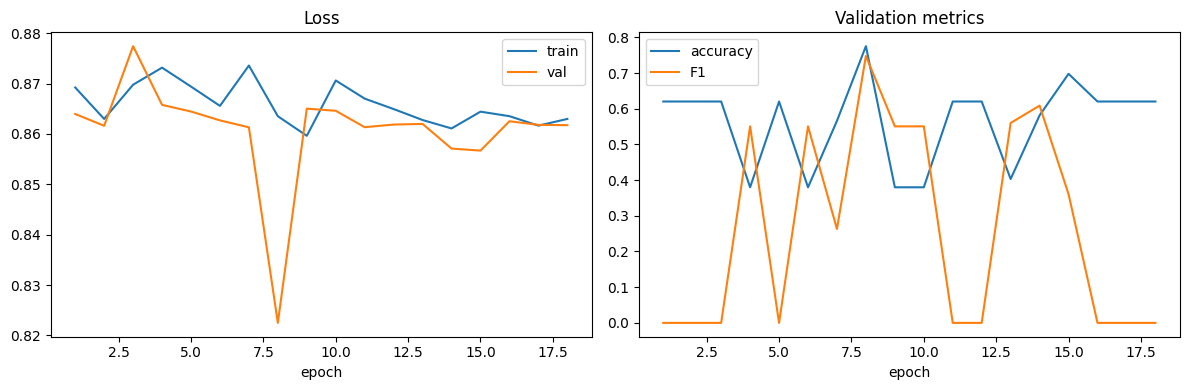

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.epoch, history.train_loss, label="train"); ax[0].plot(history.epoch, history.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(history.epoch, history.val_accuracy, label="accuracy"); ax[1].plot(history.epoch, history.val_f1, label="F1")
ax[1].set_title("Validation metrics"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 11. Evaluation on the test set
The best checkpoint (by validation F1) is loaded. The decision threshold is tuned **on the validation set only**, then applied to the test set, so there is no test leakage.

best epoch: 8 (val F1 0.7478)
threshold tuned on validation: 0.52

TEST SET RESULTS
                accuracy  precision  recall      f1
threshold 0.50    0.7054     0.5775  0.8367  0.6833
tuned (0.52)      0.7132     0.6000  0.7347  0.6606
ROC-AUC: 0.7691

               precision    recall  f1-score   support

      normal       0.81      0.70      0.75        80
 shoplifting       0.60      0.73      0.66        49

    accuracy                           0.71       129
   macro avg       0.71      0.72      0.71       129
weighted avg       0.73      0.71      0.72       129



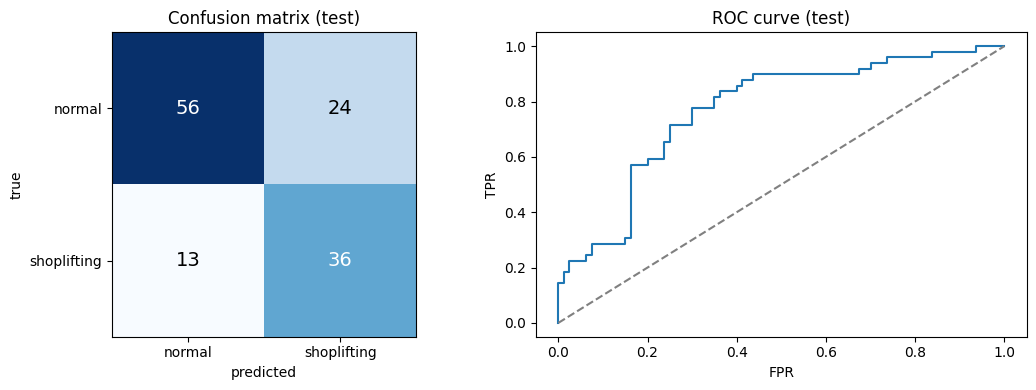

In [15]:
best = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
model = CNNBiGRU().to(DEVICE); model.load_state_dict(best["model"])
print(f"best epoch: {best['epoch'] + 1} (val F1 {best['val_f1']:.4f})")

_, vp, vl = evaluate(model, val_loader)
thresholds = np.arange(0.05, 0.96, 0.01)
best_thr = float(thresholds[int(np.argmax([f1_score(vl, (vp >= t).astype(int), zero_division=0) for t in thresholds]))])
print(f"threshold tuned on validation: {best_thr:.2f}")

_, tp, tl = evaluate(model, test_loader)
results = pd.DataFrame({"threshold 0.50": metrics_at(tp, tl, 0.5), f"tuned ({best_thr:.2f})": metrics_at(tp, tl, best_thr)}).T
print("\nTEST SET RESULTS"); print(results.round(4).to_string())
if len(set(tl)) > 1:
    print(f"ROC-AUC: {roc_auc_score(tl, tp):.4f}")
print("\n", classification_report(tl, (tp >= best_thr).astype(int), target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(tl, (tp >= best_thr).astype(int), labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(CLASS_NAMES); ax[0].set_yticklabels(CLASS_NAMES)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (test)")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
if len(set(tl)) > 1:
    fpr, tpr, _ = roc_curve(tl, tp); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "--", c="gray")
    ax[1].set_title("ROC curve (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
plt.tight_layout(); plt.show()
results.to_csv(WORK_DIR / "test_results.csv")

## 12. Inference on a single video (with attention over frames)

true label: shoplifting


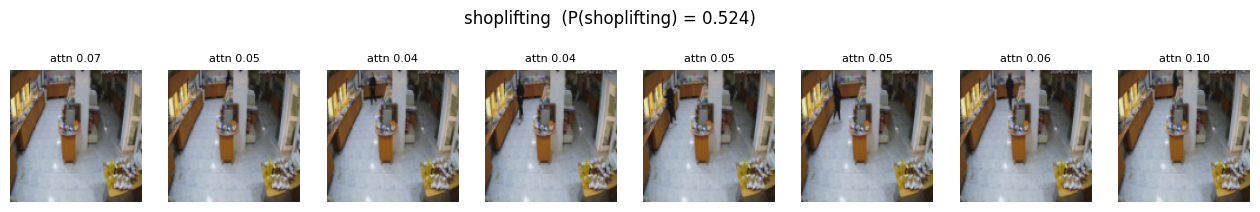

('shoplifting', 0.5239534974098206)

In [16]:
@torch.no_grad()
def predict_video(path, threshold=best_thr, show=True):
    clip = torch.from_numpy(read_sampled_frames(path, CFG["T"], CFG["cache_size"])).permute(0, 3, 1, 2).contiguous()
    x = aug_eval(clip).unsqueeze(0).to(DEVICE)
    logit, attn = model.eval()(x, return_attention=True)
    prob = torch.sigmoid(logit).item(); label = CLASS_NAMES[int(prob >= threshold)]
    if show:
        fig, axes = plt.subplots(1, 8, figsize=(16, 2.6)); frames = (x[0] * STD.to(DEVICE) + MEAN.to(DEVICE)).clamp(0, 1).cpu()
        for k, a in enumerate(axes):
            t = k * 2; a.imshow(frames[t].permute(1, 2, 0)); a.axis("off"); a.set_title(f"attn {attn[0, t]:.2f}", fontsize=8)
        fig.suptitle(f"{label}  (P(shoplifting) = {prob:.3f})"); plt.show()
    return label, prob

sample = test_df.iloc[0]
print("true label:", CLASS_NAMES[sample.label]); predict_video(sample.path) if Path(sample.path).exists() else print("(raw video not on disk; cached frames are used for training/eval)")